# Figure 16 — Sensitivity of cultural composition and cultural states

**Inputs:** all_core_run_year_metrics.csv.gz (annual run-level metrics), endpoint_2060_metrics.csv (endpoint run-level metrics), factorial_variance_decomposition.csv (response, term, percent_total). Annual metrics must contain year, r, gamma, theta, D_TV_pp, A_pct and I_pct; endpoint metrics contain the parameter and response columns.

**Dependencies:** numpy, pandas, matplotlib.

**Interpretation:** D_TV_pp uses cultural-label shares; A_pct and I_pct use model population. Lines show marginal means; intervals show 10th–90th percentiles across combinations and replicates. Vertical reference lines mark parameter values.

Input datasets are not included. The final figure is embedded as a PNG output for inspection. Set the paths below and run all cells. Outputs are PNG and SVG; existing same-name files are overwritten.

In [ ]:
from pathlib import Path
DATA = Path("input_data/sensitivity").resolve()
OUT = Path("figure_output").resolve()


In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from pathlib import Path
import argparse
from types import SimpleNamespace
source = SimpleNamespace()
source.ROOT = Path.cwd()
source.OUTPUT = source.ROOT / 'data/sensitivity'
source.PALETTE = ['#ba433b', '#ac9ada', '#cedcfc', '#bfccfe', '#ac9ada', '#bfccfe', '#ac9ada']
BASELINE = {'r': 0.002, 'gamma': 0.2, 'theta': 0.15}
PALETTE = source.PALETTE
def level_colors(levels: np.ndarray, colors: list[str]) -> dict[float, str]:
    if len(colors) < len(levels):
        raise ValueError('Not enough colours for parameter levels')
    return {float(level): color for level, color in zip(levels, colors)}
def add_time_cloud(ax: plt.Axes, data: pd.DataFrame, response: str, factor: str, colors: dict[float, tuple], ylabel: str, panel: str) -> None:
    levels = np.sort(data[factor].unique())
    run_order = {rid: i for i, rid in enumerate(sorted(data['run_id'].unique()))}
    offsets = data['run_id'].map(lambda x: (run_order[x] * 37 % 101 - 50) / 420).to_numpy()
    for level in levels:
        group = data.loc[np.isclose(data[factor], level)]
        group_offsets = offsets[group.index]
        ax.scatter(group['year'].to_numpy() + group_offsets, group[response], s=5.5, color=colors[float(level)], alpha=0.075, linewidths=0, rasterized=True)
        trajectory = group.groupby('year')[response].mean()
        ax.plot(trajectory.index, trajectory.values, color=colors[float(level)], lw=1.65, alpha=0.98)
    handles = [Line2D([0], [0], color=colors[float(level)], lw=2, label=f'{level:g}') for level in levels]
    ax.legend(handles=handles, title={'gamma': '$\\gamma$ level', 'theta': '$\\theta$ level'}[factor], loc='upper left', frameon=False, fontsize=7.1, title_fontsize=7.5, ncol=1, handlelength=1.7, borderaxespad=0.3)
    ax.set_xlim(data['year'].min() - 0.7, data['year'].max() + 0.7)
    ax.set_xticks([2020, 2030, 2040, 2050, 2060])
    ax.set_xlabel('Simulation year')
    ax.set_ylabel(ylabel)
    ax.grid(color='#E7E1E8', lw=0.6, alpha=0.78)
    ax.text(-0.12, 1.04, panel, transform=ax.transAxes, fontsize=11, fontweight='bold')
def add_endpoint_scatter(ax: plt.Axes, data: pd.DataFrame, response: str, factor: str, color: str, ylabel: str, panel: str, effect_share: float) -> None:
    levels = np.sort(data[factor].unique())
    positions = np.arange(len(levels), dtype=float)
    rng = np.random.default_rng(20261013 + len(response) + len(factor))
    for pos, level in zip(positions, levels):
        values = data.loc[np.isclose(data[factor], level), response].to_numpy()
        jitter = rng.uniform(-0.16, 0.16, size=len(values))
        ax.scatter(pos + jitter, values, s=13, facecolor=PALETTE[6], edgecolor='none', alpha=0.24, rasterized=True)
        q10, mean, q90 = np.quantile(values, [0.1, 0.5, 0.9])
        mean = values.mean()
        ax.vlines(pos, q10, q90, color=color, lw=3.1, alpha=0.72, zorder=4)
        ax.scatter(pos, mean, s=38, facecolor='white', edgecolor=color, linewidth=1.8, zorder=5)
    means = data.groupby(factor)[response].mean().reindex(levels)
    ax.plot(positions, means, color=color, lw=1.8, zorder=3)
    original_pos = int(np.flatnonzero(np.isclose(levels, BASELINE[factor]))[0])
    ax.axvline(original_pos, color='#30343B', lw=1.05, ls=(0, (3, 2)), zorder=0)
    ax.set_xticks(positions, [f'{x:g}' for x in levels])
    ax.set_xlabel({'r': '$r$', 'gamma': '$\\gamma$', 'theta': '$\\theta$'}[factor])
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', color='#E7E1E8', lw=0.6, alpha=0.78)
    ax.text(0.03, 0.96, f'Main-effect share = {effect_share:.3g}%', transform=ax.transAxes, ha='left', va='top', fontsize=8.1, color='#30343B', bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.82, 'pad': 1.5})
    ax.text(-0.12, 1.04, panel, transform=ax.transAxes, fontsize=11, fontweight='bold')
source.level_colors = level_colors
source.add_time_cloud = add_time_cloud
source.add_endpoint_scatter = add_endpoint_scatter


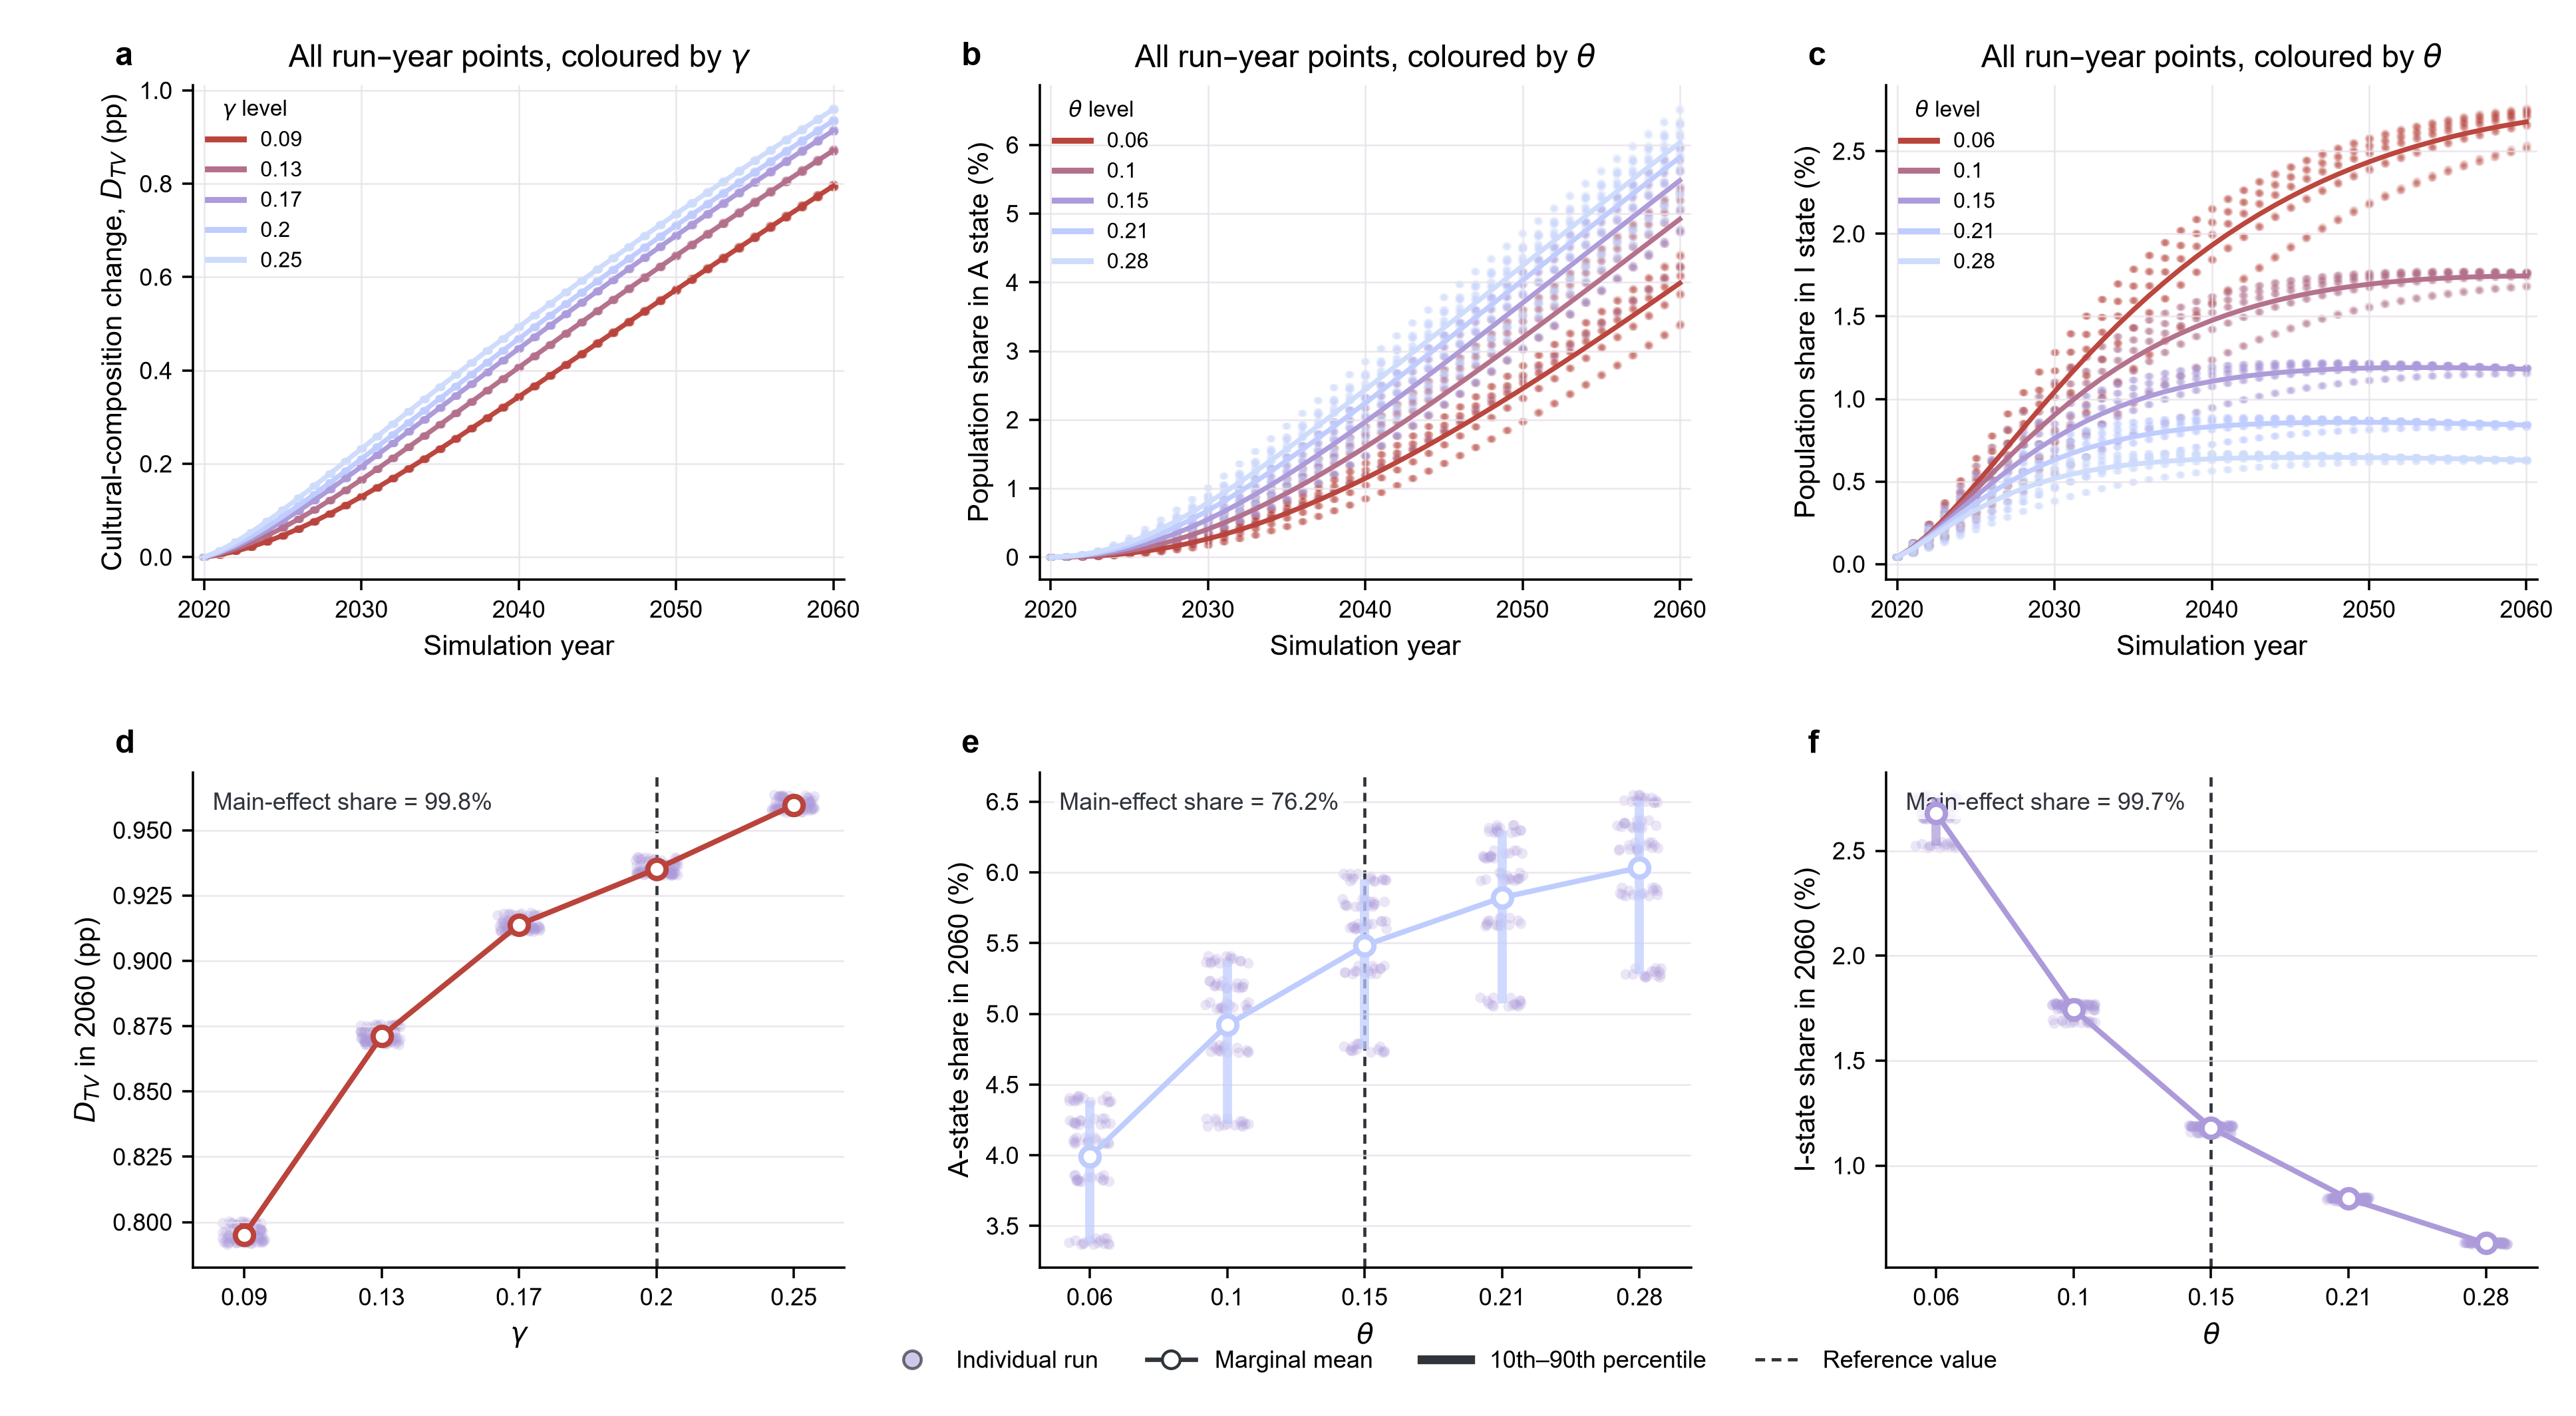

In [ ]:
OUT.mkdir(parents=True, exist_ok=True)
COLORS = ['#ba433b', '#b36f8b', '#ac9ada', '#bfccfe', '#cedcfc']
source.PALETTE[6] = '#ac9ada'
time = pd.read_csv(DATA / 'all_core_run_year_metrics.csv.gz')
endpoint = pd.read_csv(DATA / 'endpoint_2060_metrics.csv')
effects = pd.read_csv(DATA / 'factorial_variance_decomposition.csv')
def share(response, factor):
    return float(effects.loc[(effects.response == response) & (effects.term == factor), 'percent_total'].iloc[0])
mpl.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial'], 'font.size': 9, 'axes.labelsize': 9.5, 'axes.titlesize': 10.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.spines.top': False, 'axes.spines.right': False, 'svg.fonttype': 'none'})
fig, axes = plt.subplots(2, 3, figsize=(12.1, 6.65))
fig.subplots_adjust(left=0.075, right=0.985, top=0.94, bottom=0.105, wspace=0.3, hspace=0.39)
for col, (response, factor, ylabel) in enumerate([('D_TV_pp', 'gamma', 'Cultural-composition change, $D_{TV}$ (pp)'), ('A_pct', 'theta', 'Population share in A state (%)'), ('I_pct', 'theta', 'Population share in I state (%)')]):
    colors = source.level_colors(np.sort(time[factor].unique()), COLORS)
    source.add_time_cloud(axes[0, col], time, response, factor, colors, ylabel, chr(97 + col))
    symbol = '$\\gamma$' if factor == 'gamma' else '$\\theta$'
    axes[0, col].set_title('All run–year points, coloured by ' + symbol)
for col, (response, factor, color, ylabel) in enumerate([('D_TV_pp', 'gamma', '#ba433b', '$D_{TV}$ in 2060 (pp)'), ('A_pct', 'theta', '#bfccfe', 'A-state share in 2060 (%)'), ('I_pct', 'theta', '#ac9ada', 'I-state share in 2060 (%)')]):
    source.add_endpoint_scatter(axes[1, col], endpoint, response, factor, color, ylabel, chr(100 + col), share(response, factor))
handles = [Line2D([0], [0], marker='o', color='none', markerfacecolor='#ac9ada', alpha=0.55, label='Individual run'), Line2D([0], [0], marker='o', color='#30343B', markerfacecolor='white', label='Marginal mean'), Line2D([0], [0], color='#30343B', lw=3, label='10th–90th percentile'), Line2D([0], [0], color='#30343B', lw=1.1, ls=(0, (3, 2)), label='Reference value')]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.56, 0.015), fontsize=8.2)
for extension in ('png', 'svg'):
    fig.savefig(OUT / ('CSDS_full_time_scatter_no_title.' + extension), dpi=320, facecolor='white')
plt.close(fig)
print(f'Created PNG and SVG in {OUT}')
